In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

# Manually exploring the data and creating a classification function

In [6]:
# CKD: chronic kidney disease
ckd = Table.read_table('data/ckd.csv').relabeled('Blood Glucose Random', 'Glucose')
ckd.sample(5)

Age,Blood Pressure,Specific Gravity,Albumin,Sugar,Red Blood Cells,Pus Cell,Pus Cell clumps,Bacteria,Glucose,Blood Urea,Serum Creatinine,Sodium,Potassium,Hemoglobin,Packed Cell Volume,White Blood Cell Count,Red Blood Cell Count,Hypertension,Diabetes Mellitus,Coronary Artery Disease,Appetite,Pedal Edema,Anemia,Class
58,70,1.025,0,0,normal,normal,notpresent,notpresent,88,16,1.1,147,3.5,16.4,53,9100,5.2,no,no,no,good,no,no,0
56,80,1.025,0,0,normal,normal,notpresent,notpresent,139,15,1.2,135,5,14.8,42,5600,5.5,no,no,no,good,no,no,0
71,70,1.01,3,0,normal,abnormal,present,present,219,82,3.6,133,4.4,10.4,33,5600,3.6,yes,yes,yes,good,no,no,1
17,60,1.025,0,0,normal,normal,notpresent,notpresent,114,50,1,135,4.9,14.2,51,7200,5.9,no,no,no,good,no,no,0
33,80,1.025,0,0,normal,normal,notpresent,notpresent,89,19,1.1,144,5,15,40,10300,4.8,no,no,no,good,no,no,0


In [8]:
shuffled_ckd = ckd.sample(with_replacement=False)
shuffled_ckd.num_rows

158

In [12]:
training_set = shuffled_ckd.take(np.arange(100))
test_set = shuffled_ckd.take(np.arange(100, 158))

In [13]:
training_set

Age,Blood Pressure,Specific Gravity,Albumin,Sugar,Red Blood Cells,Pus Cell,Pus Cell clumps,Bacteria,Glucose,Blood Urea,Serum Creatinine,Sodium,Potassium,Hemoglobin,Packed Cell Volume,White Blood Cell Count,Red Blood Cell Count,Hypertension,Diabetes Mellitus,Coronary Artery Disease,Appetite,Pedal Edema,Anemia,Class
46,70,1.025,0,0,normal,normal,notpresent,notpresent,100,47,0.5,142,3.5,16.4,43,5700,6.5,no,no,no,good,no,no,0
68,60,1.025,0,0,normal,normal,notpresent,notpresent,125,41,1.1,139,3.8,17.4,50,6700,6.1,no,no,no,good,no,no,0
46,60,1.02,0,0,normal,normal,notpresent,notpresent,102,27,0.7,142,4.9,13.2,44,11000,5.4,no,no,no,good,no,no,0
22,60,1.025,0,0,normal,normal,notpresent,notpresent,97,18,1.2,138,4.3,13.5,42,7900,6.4,no,no,no,good,no,no,0
62,70,1.025,3,0,normal,abnormal,notpresent,notpresent,122,42,1.7,136,4.7,12.6,39,7900,3.9,yes,yes,no,good,no,no,1
57,60,1.02,0,0,normal,normal,notpresent,notpresent,132,18,1.1,150,4.7,15.4,42,11000,4.5,no,no,no,good,no,no,0
73,60,1.02,0,0,normal,normal,notpresent,notpresent,127,48,0.5,150,3.5,15.1,52,11000,4.7,no,no,no,good,no,no,0
42,80,1.02,0,0,normal,normal,notpresent,notpresent,98,20,0.5,140,3.5,13.9,44,8400,5.5,no,no,no,good,no,no,0
71,70,1.02,0,0,normal,normal,notpresent,notpresent,81,18,0.8,145,5,14.7,44,9800,6,no,no,no,good,no,no,0
58,70,1.025,0,0,normal,normal,notpresent,notpresent,88,16,1.1,147,3.5,16.4,53,9100,5.2,no,no,no,good,no,no,0


In [14]:
training_set.group('Class')

Class,count
0,74
1,26


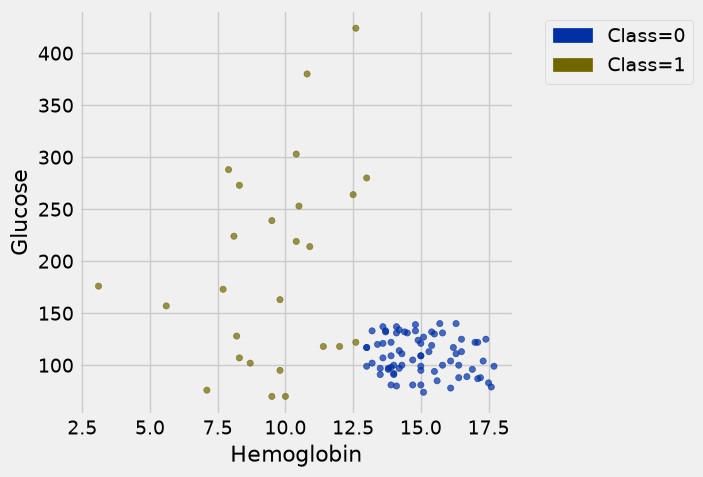

In [17]:
training_set.scatter('Hemoglobin', 'Glucose', group='Class')

In [18]:
min_hemoglobin_for_0 = training_set.where('Class', 0).column('Hemoglobin').min()
max_glucose_for_0 = training_set.where('Class', 0).column('Glucose').max()
min_hemoglobin_for_0, max_glucose_for_0

(13.0, 140)

In [19]:
# Crushed ICE: create a function called classify_manually that takes hemoglobin and
# glucose values, and returns a classification of 1 or 0
def classify_manually(hemoglobin, glucose):
    if hemoglobin >= min_hemoglobin_for_0 and glucose <= max_glucose_for_0:
        return 0
    else:
        return 1

In [20]:
classify_manually(15, 100)

0

In [21]:
classify_manually(10, 300)

1

In [25]:
classifications = test_set.select('Hemoglobin', 'Glucose').apply(classify_manually, 0, 1)
classifications

array([0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1])

In [27]:
test_set.column('Class')

array([0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1])

In [29]:
(classifications == test_set.column('Class')).mean()

1.0

## Sometimes 2 dimensions isn't enough

In [30]:
banknotes = Table.read_table('data/banknote.csv')
banknotes.sample()

WaveletVar,WaveletSkew,WaveletCurt,Entropy,Class
-1.8187,-9.0366,9.0162,-0.12243,1
0.87603,6.8141,0.84198,-0.17156,0
-1.8391,-9.0883,9.2416,-0.10432,1
-1.4427,3.2922,-1.9702,-3.4392,1
-2.2183,-1.254,2.9986,0.36378,1
-2.565,-5.7899,6.0122,0.046968,1
2.0177,1.7982,-2.9581,0.2099,1
-1.7101,-8.7903,7.9735,-0.45475,1
-1.1391,1.8127,6.9144,0.70127,0
-3.3203,-0.02691,2.9618,-0.44958,1


In [31]:
banknotes.group('Class')

Class,count
0,762
1,610


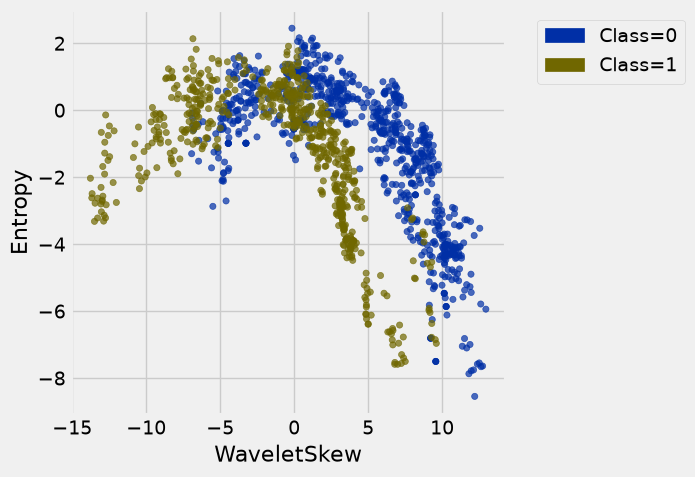

In [32]:
banknotes.scatter('WaveletSkew', 'Entropy', group='Class')

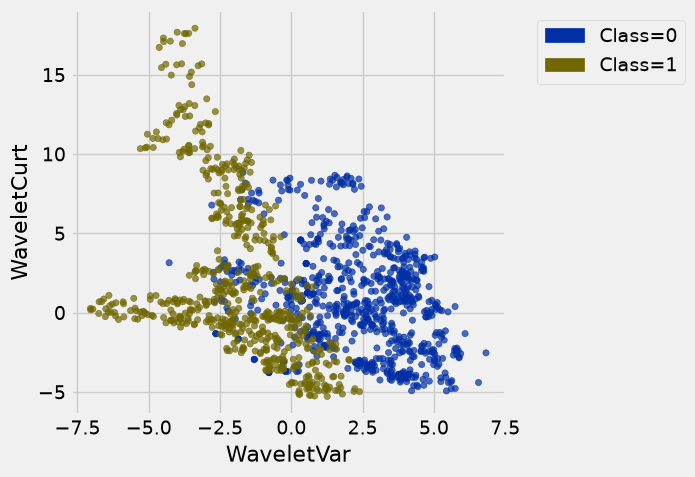

In [33]:
banknotes.scatter('WaveletVar', 'WaveletCurt', group='Class')

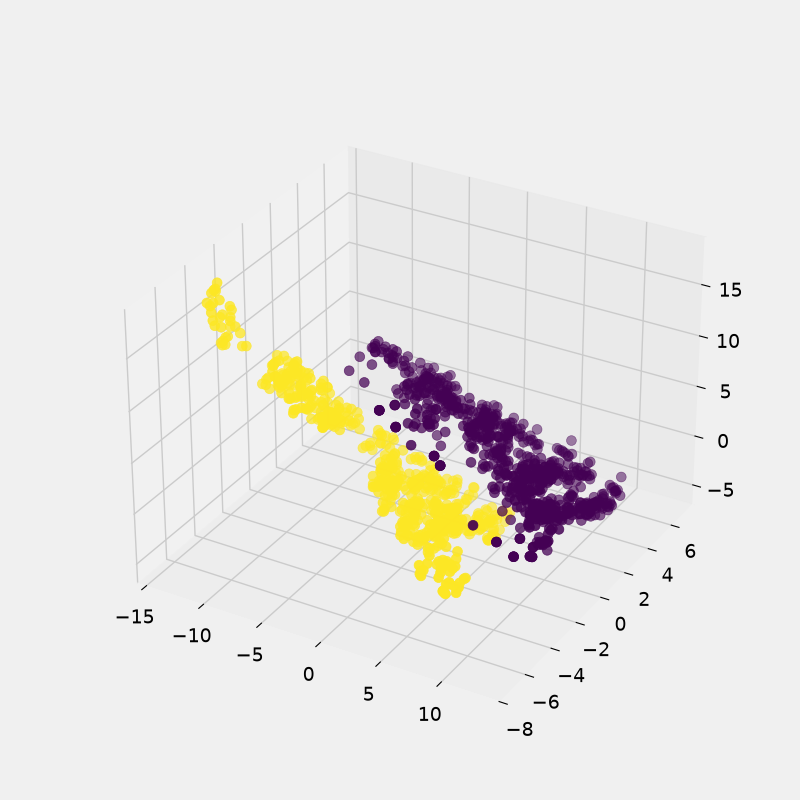

In [34]:
%matplotlib widget
from mpl_toolkits.mplot3d import Axes3D
ax = plt.figure(figsize=(8,8)).add_subplot(111, projection='3d')
ax.scatter(banknotes.column('WaveletSkew'), 
           banknotes.column('WaveletVar'), 
           banknotes.column('WaveletCurt'), 
           c=banknotes.column('Class'),
           cmap='viridis',
          s=50);

# Pre-made nearest neighbor classifier example (k=1)

In [35]:
# don't worry about any of this right now

%matplotlib inline

def standard_units(x):
    return (x - np.mean(x))/np.std(x)

def distance(point1, point2):
    """The distance between two arrays of numbers."""
    return np.sqrt(np.sum((point1 - point2)**2))

def all_distances(training, point):
    """The distance between p (an array of numbers) and the numbers in row i of attribute_table."""
    attributes = training.drop('Class')
    def distance_from_point(row):
        return distance(point, np.array(row))
    return attributes.apply(distance_from_point)

def table_with_distances(training, point):
    """A copy of the training table with the distance from each row to array p."""
    return training.with_column('Distance', all_distances(training, point))

def closest(training, point, k):
    """A table containing the k closest rows in the training table to array p."""
    with_dists = table_with_distances(training, point)
    sorted_by_distance = with_dists.sort('Distance')
    topk = sorted_by_distance.take(np.arange(k))
    return topk

def majority(topkclasses):
    """1 if the majority of the "Class" column is 1s, and 0 otherwise."""
    ones = topkclasses.where('Class', are.equal_to(1)).num_rows
    zeros = topkclasses.where('Class', are.equal_to(0)).num_rows
    if ones > zeros:
        return 1
    else:
        return 0

def classify(training, p, k):
    """Classify an example with attributes p using k-nearest neighbor classification with the given training table."""
    closestk = closest(training, p, k)
    topkclasses = closestk.select('Class')
    return majority(topkclasses)

def show_closest(point):
    """point = array([x,y]) 
    gives the coordinates of a new point
    shown in red"""
    
    HemoGl = ckd.select('Hemoglobin', 'Glucose')
    t = closest(HemoGl, point, 1)
    x_closest = t.row(0).item(0)
    y_closest = t.row(0).item(1)
    ckd.scatter('Hemoglobin', 'Glucose', group='Class')
    plt.scatter(point.item(0), point.item(1), color='red', s=30)
    plt.plot(make_array(point.item(0), x_closest), make_array(point.item(1), y_closest), color='k', lw=2);

def plot_all_points(test_grid):
    test_grid.scatter('Hemoglobin', 'Glucose', color='red', alpha=0.4, s=30)

    plt.scatter(ckd.column('Hemoglobin'), ckd.column('Glucose'), c=ckd.column('Class'), edgecolor='k')

    plt.xlim(-2, 2)
    plt.ylim(-2, 2);
    
def classify_grid(training, test, k):
    c = make_array()
    for i in range(test.num_rows):
        # Run the classifier on the ith patient in the test set
        c = np.append(c, classify(training, make_array(test.row(i)), k))   
    return c

def plot_all_points_classified(test_grid):
    c = classify_grid(ckd.drop('White Blood Cell Count'), test_grid, 1)
    test_grid = test_grid.with_column('Class', c)
    test_grid.scatter('Hemoglobin', 'Glucose', group='Class', alpha=0.4, s=30)
    
    plt.scatter(ckd.column('Hemoglobin'), ckd.column('Glucose'), c=ckd.column('Class'), edgecolor='k')

    plt.xlim(-2, 2)
    plt.ylim(-2, 2);

In [36]:
ckd = Table.read_table('data/ckd.csv').relabeled('Blood Glucose Random', 'Glucose')
ckd = Table().with_columns(
    'Hemoglobin', standard_units(ckd.column('Hemoglobin')),
    'Glucose', standard_units(ckd.column('Glucose')),
    'White Blood Cell Count', standard_units(ckd.column('White Blood Cell Count')),
    'Class', ckd.column('Class')
)

ckd.sample()

Hemoglobin,Glucose,White Blood Cell Count,Class
0.804944,-0.576849,-1.01892,0
0.0740178,-0.515058,-0.0243664,0
-1.35303,0.489051,1.96475,1
-0.0304002,-0.376028,0.5852,0
-0.587296,-0.206101,-0.0243664,1
1.1182,-0.545954,-0.409356,0
0.804944,-0.576849,-1.01892,0
-1.00497,3.84123,-1.27558,1
0.700526,-0.128862,-0.698098,0
0.108824,-0.484162,-0.569768,0


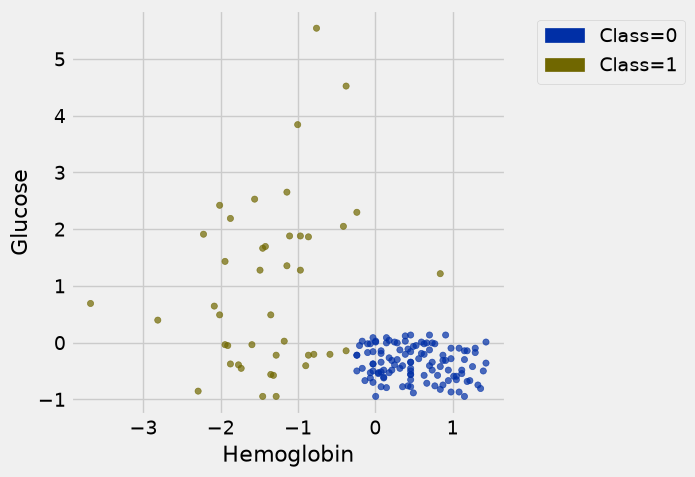

In [38]:
ckd.scatter('Hemoglobin', 'Glucose', group='Class')

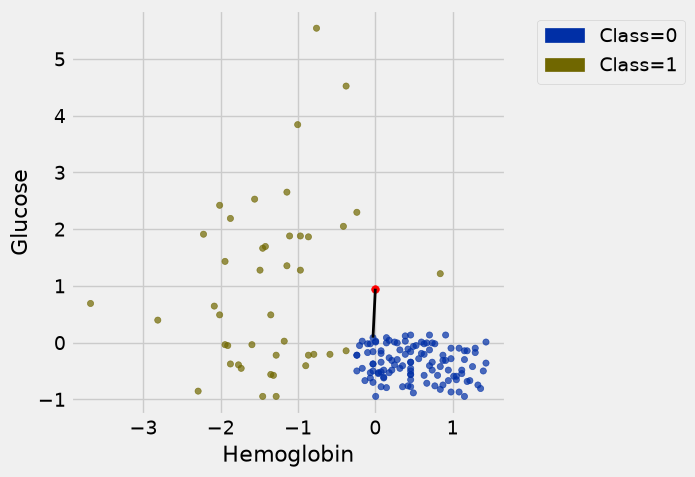

In [39]:
alice = make_array(0, 0.95) # now in standard units
show_closest(alice)

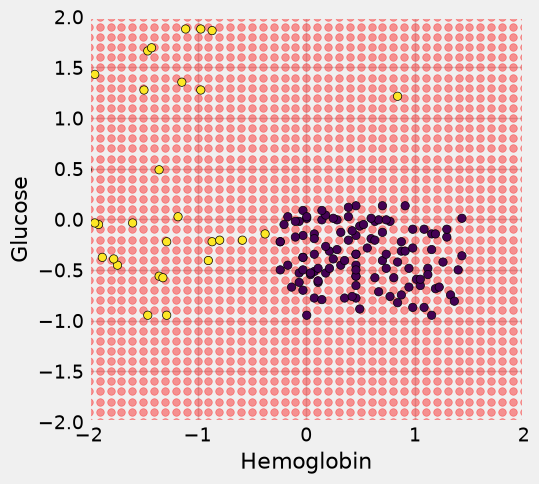

In [40]:
x_array = make_array()
y_array = make_array()
for x in np.arange(-2, 2.1, 0.1):
    for y in np.arange(-2, 2.1, 0.1):
        x_array = np.append(x_array, x)
        y_array = np.append(y_array, y)

test_grid = Table().with_columns(
    'Hemoglobin', x_array,
    'Glucose', y_array
)

plot_all_points(test_grid)

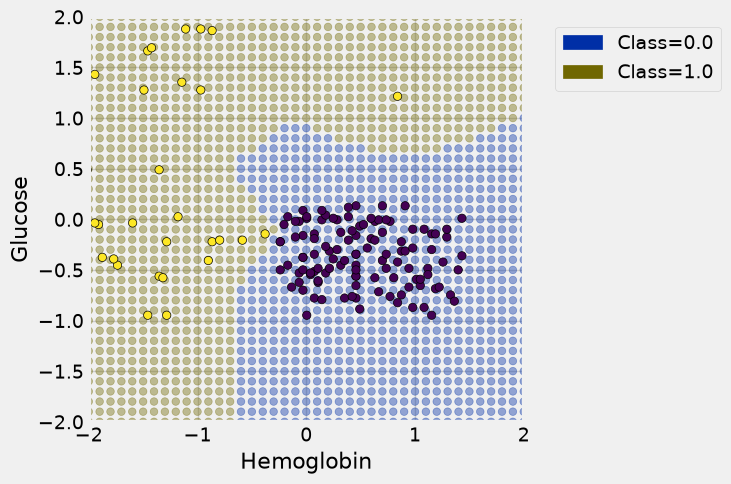

In [41]:
plot_all_points_classified(test_grid)

# k-Nearest Neighbors from scratch this time

## Calculating distance

In [42]:
ckd = Table.read_table('data/ckd.csv').relabeled('Blood Glucose Random', 'Glucose')
ckd = ckd.select('Hemoglobin', 'Glucose', 'Class')
ckd

Hemoglobin,Glucose,Class
11.2,117,1
9.5,70,1
10.8,380,1
5.6,157,1
7.7,173,1
9.8,95,1
12.5,264,1
10,70,1
10.5,253,1
9.8,163,1


In [46]:
alice = make_array(10, 250)
alice

array([ 10, 250])

In [45]:
# Goal: find the distance from Alice to everyone in the dataset

In [50]:
patient1 = ckd.drop('Class').row(0)
patient1

Row(Hemoglobin=11.199999999999999, Glucose=117)

In [51]:
type(patient1)

datascience.tables.Row

In [53]:
((alice.item(0) - patient1.item(0))**2 + (alice.item(1) - patient1.item(1))**2) ** 0.5

133.00541342366483

In [54]:
# ^ if patient1 was an array, this process could be faster!

In [56]:
np.array(patient1)

array([  11.2,  117. ])

In [57]:
alice - np.array(patient1)

array([  -1.2,  133. ])

In [58]:
(alice - np.array(patient1)) ** 2

array([  1.44000000e+00,   1.76890000e+04])

In [59]:
np.sum((alice - np.array(patient1)) ** 2)

17690.439999999999

In [60]:
np.sum((alice - np.array(patient1)) ** 2) ** 0.5

133.00541342366483

In [ ]:
# Crushed ICE: create a distance(point1, point2) function that returns the distance
# between the two points (that are represented as arrays)

In [ ]:
distance(alice, np.array(patient1))